# Visualisierung von Rekursionsbäumen: Fibonacci-Berechnung (Brute Force vs. Memoization)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/dgaida/ba_algo_th_public/blob/main/assets/exercises/week_13/fibonacci_recursion_trees.ipynb)

Dieses interaktive Notebook visualisiert das **Fibonacci-Problem** für $n = 5$ anhand von Rekursionsbäumen:
1. **Brute-Force Rekursion**: Visualisierung des vollständigen exponentiellen Rekursionsbaums inklusive aller redundanten Berechnungen.
2. **Memoization (Top-Down Dynamic Programming)**: Visualisierung des beschnittenen Aufrufbaums mit Kennzeichnung von Cache-Treffern (Memo-Hits).
3. **Zustand des Memory (Cache)**: Detaillierte Ausgabe des Caches (`memo`) für jede Rekursionstiefe und jeden Schritt des Algorithmus.
4. **Vergleich und Analyse**: Gegenüberstellung von Aufrufanzahl, Baumgröße und Zeitkomplexität ($O(2^n)$ vs. $O(n)$).

## 1. Theoretische Grundlagen

Die Fibonacci-Folge ist definiert durch die Rekurrenz:
$$
\text{fib}(n) = 
\begin{cases} 
0, & \text{wenn } n = 0 \\ 
1, & \text{wenn } n = 1 \\ 
\text{fib}(n-1) + \text{fib}(n-2), & \text{wenn } n > 1 
\end{cases}
$$

### Naive rekursive Lösung (Brute Force)
Beim naiven rekursiven Ansatz führt jeder Aufruf $\text{fib}(n)$ ($n > 1$) zu zwei weiteren rekursiven Teilaufrufen:
- $\text{fib}(n-1)$
- $\text{fib}(n-2)$

Da Teilprobleme mehrfach unabhängig voneinander neu gelöst werden (überlappende Teilprobleme / *overlapping subproblems*), wächst der Rekursionsbaum exponentiell ($O(2^n)$ bzw. $O(\phi^n)$ mit dem Goldenen Schnitt $\phi \approx 1.618$).
Für $n = 5$ führt die naive Berechnung bereits zu **15 Funktionsaufrufen**.

### Dynamische Programmierung mit Memoization (Top-Down)
Bei der **Memoization** wird das Ergebnis für jedes $n$ beim ersten Berechnen in einem assoziativen Speicher (Dictionary / Hashtabelle `memo`) abgelegt.
- Bevor ein Teilproblem berechnet wird, prüft der Algorithmus: `if n in memo: return memo[n]`.
- Jeder Zustand $n \in \{0, 1, \dots, 5\}$ wird somit **genau einmal** berechnet.
- Jeder erneute Aufruf wird sofort aus dem Speicher in $O(1)$ bedient und erzeugt keine weiteren Kindknoten im Rekursionsbaum.
- Dadurch reduziert sich die Anzahl der Funktionsaufrufe für $n=5$ von 15 auf nur noch **9 Aufrufe** (bzw. 6 Berechnungen und 3 Cache-Treffer), und die Zeitkomplexität sinkt auf **$O(n)$**.

In [1]:
import matplotlib.pyplot as plt
import networkx as nx
import pandas as pd
from collections import defaultdict
from IPython.display import display, Markdown

# Globale Plot-Einstellungen
plt.rcParams["figure.dpi"] = 120
plt.rcParams["font.size"] = 10


## 2. Datenstrukturen & Baum-Layout-Algorithmus

Um die Rekursionsbäume übersichtlich und hierarchisch nach Rekursionstiefe darzustellen, definieren wir:
- Eine Knotenklasse `TreeNode`, die Metadaten wie Aufruf-ID, Eingabewert $n$, Tiefe, Rückgabewert, Flag für Cache-Treffer und den Speicherzustand (`memo`) speichert.
- Einen hierarchischen Layout-Algorithmus `compute_tree_layout`, der die x-Koordinaten der Blätter von links nach rechts anordnet und Elternknoten zentriert über ihren Kindern platziert.

In [2]:
class TreeNode:
    """Repräsentiert einen Knoten im Rekursionsbaum."""
    def __init__(self, node_id, n, depth, branch="root"):
        self.node_id = node_id
        self.n = n
        self.depth = depth
        self.branch = branch  # 'left' (n-1), 'right' (n-2) oder 'root'
        self.value = None
        self.is_memo_hit = False
        self.memo_before = {}
        self.memo_after = {}
        self.children = []

def compute_tree_layout(root):
    """Berechnet 2D-Koordinaten für einen hierarchischen Rekursionsbaum."""
    pos = {}
    leaf_x = 0.0

    def assign_pos(node):
        nonlocal leaf_x
        y = -node.depth * 1.5
        if not node.children:
            x = leaf_x
            leaf_x += 1.8
            pos[node.node_id] = (x, y)
            return x
        child_xs = []
        for c in node.children:
            child_xs.append(assign_pos(c))
        x = sum(child_xs) / len(child_xs)
        pos[node.node_id] = (x, y)
        return x

    assign_pos(root)
    return pos


## 3. Brute-Force Rekursion für $\text{fib}(5)$

Wir zeichnen alle Funktionsaufrufe von `fibonacci_recursive(5)` chronologisch auf und konstruieren den vollständigen Aufrufbaum.
Jeder Aufruf $\text{fib}(n)$ mit $n > 1$ ruft zuerst den linken Kindknoten $\text{fib}(n-1)$ und anschließend den rechten Kindknoten $\text{fib}(n-2)$ auf.

In [3]:
call_counter_bf = 0
bf_calls_trace = []

def fib_recursive_traced(n, depth=0, branch="root"):
    global call_counter_bf
    call_counter_bf += 1
    current_id = call_counter_bf
    node = TreeNode(current_id, n, depth, branch)
    bf_calls_trace.append({
        "call_id": current_id,
        "n": n,
        "depth": depth,
        "branch": branch
    })
    
    if n <= 1:
        node.value = n
        bf_calls_trace[-1]["result"] = n
        return node
    
    left_child = fib_recursive_traced(n - 1, depth + 1, "left")
    right_child = fib_recursive_traced(n - 2, depth + 1, "right")
    node.children = [left_child, right_child]
    node.value = left_child.value + right_child.value
    bf_calls_trace[-1]["result"] = node.value
    return node

# Baum für fib(5) erzeugen
call_counter_bf = 0
bf_calls_trace.clear()
root_bf = fib_recursive_traced(5)

print(f"Brute-Force Berechnung abgeschlossen: fib(5) = {root_bf.value}")
print(f"Gesamtzahl der Funktionsaufrufe (Knoten im Rekursionsbaum): {call_counter_bf}")


Brute-Force Berechnung abgeschlossen: fib(5) = 5
Gesamtzahl der Funktionsaufrufe (Knoten im Rekursionsbaum): 15


### Visualisierung des Brute-Force Rekursionsbaums

Im folgenden Diagramm sehen wir den finalen Rekursionsbaum für $\text{fib}(5)$:
- **Knotenbeschriftung**: `#ID: fib(n) = Wert`
- **Farben**:
  - **Grün**: Basisfälle $\text{fib}(1) = 1$ und $\text{fib}(0) = 0$.
  - **Blau/Orange/Rot**: Rekursive Aufrufe. Gleiche Teilprobleme (z. B. $\text{fib}(3)$ und $\text{fib}(2)$) sind farblich hervorgehoben, um die Redundanz sichtbar zu machen.
- **Kantenbeschriftung**: Zeigt den jeweiligen Rekursionszweig ($n-1$ oder $n-2$).

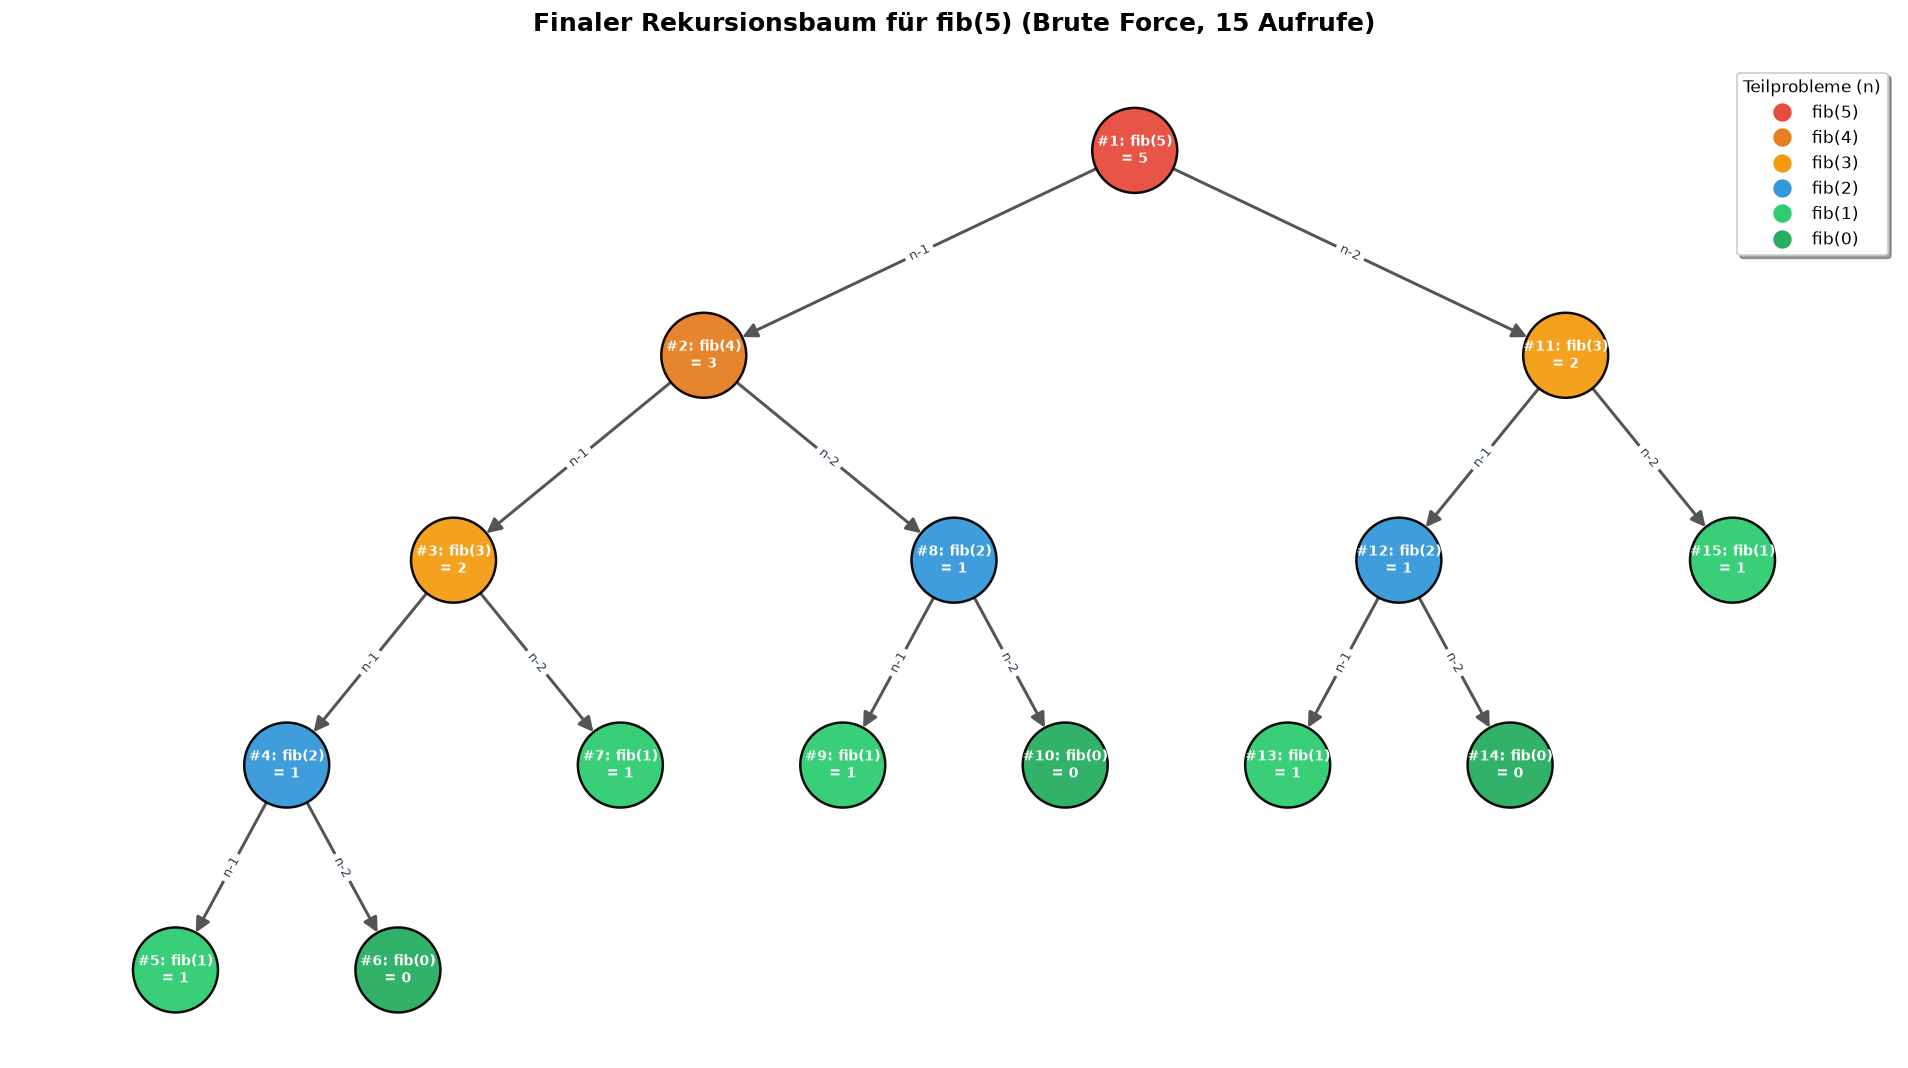

In [4]:
def draw_recursion_tree_bf(root):
    """Zeichnet den finalen Rekursionsbaum der Brute-Force-Berechnung."""
    G = nx.DiGraph()
    nodes_dict = {}
    edge_labels = {}

    def traverse(node):
        nodes_dict[node.node_id] = node
        G.add_node(node.node_id)
        for c in node.children:
            G.add_edge(node.node_id, c.node_id)
            edge_label = f"n-{node.n - c.n}"
            edge_labels[(node.node_id, c.node_id)] = edge_label
            traverse(c)

    traverse(root)
    pos = compute_tree_layout(root)

    # Farbpalette nach Eingabewert n zur Verdeutlichung redundanter Teilprobleme
    color_palette = {
        5: "#e74c3c",  # Rot (Wurzel)
        4: "#e67e22",  # Orange
        3: "#f39c12",  # Gelb/Gold
        2: "#3498db",  # Blau
        1: "#2ecc71",  # Grün (Basisfall)
        0: "#27ae60"   # Dunkelgrün (Basisfall)
    }
    node_colors = [color_palette[nodes_dict[uid].n] for uid in G.nodes()]

    # Labels: #Aufruf: fib(n) = val
    labels = {
        uid: f"#{uid}: fib({nodes_dict[uid].n})\n= {nodes_dict[uid].value}"
        for uid in G.nodes()
    }

    plt.figure(figsize=(16, 9))
    plt.title("Finaler Rekursionsbaum für fib(5) (Brute Force, 15 Aufrufe)", fontsize=15, fontweight="bold", pad=20)

    nx.draw_networkx_nodes(G, pos, node_color=node_colors, node_size=2600, alpha=0.95, edgecolors="black", linewidths=1.5)
    nx.draw_networkx_edges(G, pos, arrows=True, arrowstyle="-| >", arrowsize=18, edge_color="#555555", width=1.8, node_size=2600)
    nx.draw_networkx_labels(G, pos, labels=labels, font_size=8.5, font_weight="bold", font_color="white")
    nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels, font_size=8, font_color="#2c3e50")

    # Legende für Farbkodierung
    legend_elements = [
        plt.Line2D([0], [0], marker="o", color="w", markerfacecolor=color_palette[n], markersize=12, label=f"fib({n})")
        for n in [5, 4, 3, 2, 1, 0]
    ]
    plt.legend(handles=legend_elements, loc="upper right", title="Teilprobleme (n)", frameon=True, shadow=True)
    
    plt.axis("off")
    plt.tight_layout()
    plt.show()

draw_recursion_tree_bf(root_bf)


### Redundanz-Analyse der Brute-Force-Lösung

Wir analysieren, wie oft jedes Teilproblem im Brute-Force-Baum berechnet wird:

In [5]:
df_bf = pd.DataFrame(bf_calls_trace)
freq_df = df_bf["n"].value_counts().sort_index(ascending=False).reset_index()
freq_df.columns = ["Teilproblem n", "Anzahl Aufrufe im Baum"]
fib_vals = {0: 0, 1: 1, 2: 1, 3: 2, 4: 3, 5: 5}
freq_df["Ergebnis fib(n)"] = freq_df["Teilproblem n"].map(fib_vals)
freq_df["Redundant berechnet?"] = freq_df["Anzahl Aufrufe im Baum"].apply(lambda c: f"Ja ({c}x)" if c > 1 else "Nein (1x)")

print("Übersicht der Häufigkeit jedes Teilproblems:")
display(freq_df)


Übersicht der Häufigkeit jedes Teilproblems:


,Teilproblem n,Anzahl Aufrufe im Baum,Ergebnis fib(n),Redundant berechnet?
0,5,1,5,Nein (1x)
1,4,1,3,Nein (1x)
2,3,2,2,Ja (2x)
3,2,3,1,Ja (3x)
4,1,5,1,Ja (5x)
5,0,3,0,Ja (3x)


## 4. Rekursion mit Memoization für $\text{fib}(5)$

Nun implementieren wir die Top-Down Dynamic Programming Lösung mit **Memoization**.
Dabei erfassen wir für jeden Aufruf und jede Rekursionstiefe:
- Den Zustand des `memory` vor der Ausführung des Aufrufs,
- Ob ein **Memo-Hit (Cache-Treffer)** vorliegt,
- Den Zustand des `memory` nach der Berechnung und Speicherung des Rückgabewerts.

### Ausgabe des Memory in jeder Rekursionstiefe
Wie gefordert, geben wir das Memory (`memo`) in jeder Rekursionstiefe detailliert aus.

In [6]:
call_counter_memo = 0
memo_events_trace = []

def fibonacci_memoization_traced(n, memo=None, depth=0, branch="root"):
    """
    Berechnet fib(n) rekursiv mit Memoization und zeichnet jeden Aufruf,
    jede Rekursionstiefe und den jeweiligen Speicherzustand auf.
    """
    global call_counter_memo
    if memo is None:
        memo = {}
    
    call_counter_memo += 1
    current_id = call_counter_memo
    node = TreeNode(current_id, n, depth, branch)
    node.memo_before = dict(memo)
    
    # Event für den Aufruf registrieren
    memo_events_trace.append({
        "step": len(memo_events_trace) + 1,
        "event_type": "Aufruf",
        "call_id": current_id,
        "n": n,
        "depth": depth,
        "branch": branch,
        "memo_state": dict(memo),
        "info": f"Aufruf #{current_id}: fib({n})"
    })
    
    # Prüfen, ob Ergebnis bereits im Memory gespeichert ist
    if n in memo:
        node.is_memo_hit = True
        node.value = memo[n]
        node.memo_after = dict(memo)
        memo_events_trace.append({
            "step": len(memo_events_trace) + 1,
            "event_type": "Memo-Hit",
            "call_id": current_id,
            "n": n,
            "depth": depth,
            "branch": branch,
            "memo_state": dict(memo),
            "info": f"⚡ Memo-Hit! fib({n}) = {memo[n]} direkt aus Memory geladen (kein Teilbaum)"
        })
        return node
    
    # Basisfall
    if n <= 1:
        memo[n] = n
        node.value = n
    else:
        left_child = fibonacci_memoization_traced(n - 1, memo, depth + 1, "left")
        right_child = fibonacci_memoization_traced(n - 2, memo, depth + 1, "right")
        node.children = [left_child, right_child]
        memo[n] = left_child.value + right_child.value
        node.value = memo[n]
        
    node.memo_after = dict(memo)
    memo_events_trace.append({
        "step": len(memo_events_trace) + 1,
        "event_type": "Berechnet & Gespeichert",
        "call_id": current_id,
        "n": n,
        "depth": depth,
        "branch": branch,
        "memo_state": dict(memo),
        "info": f"✓ fib({n}) = {node.value} berechnet und in memo[{n}] abgelegt"
    })
    return node

# Berechnung durchführen
shared_memo = {}
call_counter_memo = 0
memo_events_trace.clear()
root_memo = fibonacci_memoization_traced(5, shared_memo)

print(f"Memoization Berechnung abgeschlossen: fib(5) = {root_memo.value}")
print(f"Gesamtzahl der Funktionsaufrufe mit Memoization: {call_counter_memo}")
print(f"Finaler Memory-Inhalt: {shared_memo}")


Memoization Berechnung abgeschlossen: fib(5) = 5
Gesamtzahl der Funktionsaufrufe mit Memoization: 9
Finaler Memory-Inhalt: {1: 1, 0: 0, 2: 1, 3: 2, 4: 3, 5: 5}


### Tabellarische und detaillierte Ausgabe des Memory je Rekursionstiefe

Hier zeigen wir den exakten Ablauf und die Entwicklung des Speichers (`memory`) für jede Rekursionstiefe:
1. Gruppiert nach **Rekursionstiefe** (Tiefe 0 bis 4).
2. Chronologisch Schritt für Schritt als Tabelle.

In [7]:
# 1. Strukturierte Ausgabe gruppiert nach Rekursionstiefe
events_by_depth = defaultdict(list)
for ev in memo_events_trace:
    events_by_depth[ev["depth"]].append(ev)

print("=" * 80)
print("AUSGABE DES MEMORY NACH REKURSIONSTIEFE (DEPTH 0 BIS 4)")
print("=" * 80)

for depth in sorted(events_by_depth.keys()):
    print(f"\n>>> REKURSIONSTIEFE {depth}:")
    print("-" * 70)
    for ev in events_by_depth[depth]:
        memo_str = str(dict(sorted(ev["memo_state"].items()))) if ev["memo_state"] else "{} (leer)"
        print(f"  • Schritt {ev['step']:2d} | Event: {ev['event_type']:<22} | {ev['info']}")
        print(f"    Memory-Zustand: {memo_str}")
    print("-" * 70)

# 2. Chronologische tabellarische Darstellung aller Schritte
df_memo_trace = pd.DataFrame([
    {
        "Schritt": ev["step"],
        "Tiefe": ev["depth"],
        "Aufruf": f"#{ev['call_id']}: fib({ev['n']})",
        "Ereignis": ev["event_type"],
        "Memory (Cache)": str(dict(sorted(ev["memo_state"].items()))) if ev["memo_state"] else "{}",
        "Details / Aktion": ev["info"]
    }
    for ev in memo_events_trace
])

display(Markdown("### Vollständige Chronologie der Memory-Zustände:"))
display(df_memo_trace)


AUSGABE DES MEMORY NACH REKURSIONSTIEFE (DEPTH 0 BIS 4)

>>> REKURSIONSTIEFE 0:
----------------------------------------------------------------------
  • Schritt  1 | Event: Aufruf                 | Aufruf #1: fib(5)
    Memory-Zustand: {} (leer)
  • Schritt 18 | Event: Berechnet & Gespeichert | ✓ fib(5) = 5 berechnet und in memo[5] abgelegt
    Memory-Zustand: {0: 0, 1: 1, 2: 1, 3: 2, 4: 3, 5: 5}
----------------------------------------------------------------------

>>> REKURSIONSTIEFE 1:
----------------------------------------------------------------------
  • Schritt  2 | Event: Aufruf                 | Aufruf #2: fib(4)
    Memory-Zustand: {} (leer)
  • Schritt 15 | Event: Berechnet & Gespeichert | ✓ fib(4) = 3 berechnet und in memo[4] abgelegt
    Memory-Zustand: {0: 0, 1: 1, 2: 1, 3: 2, 4: 3}
  • Schritt 16 | Event: Aufruf                 | Aufruf #9: fib(3)
    Memory-Zustand: {0: 0, 1: 1, 2: 1, 3: 2, 4: 3}
  • Schritt 17 | Event: Memo-Hit               | ⚡ Memo-Hit! fib(3) =

### Vollständige Chronologie der Memory-Zustände:

,Schritt,Tiefe,Aufruf,Ereignis,Memory (Cache),Details / Aktion
0,1,0,#1: fib(5),Aufruf,{},Aufruf #1: fib(5)
1,2,1,#2: fib(4),Aufruf,{},Aufruf #2: fib(4)
2,3,2,#3: fib(3),Aufruf,{},Aufruf #3: fib(3)
3,4,3,#4: fib(2),Aufruf,{},Aufruf #4: fib(2)
4,5,4,#5: fib(1),Aufruf,{},Aufruf #5: fib(1)
5,6,4,#5: fib(1),Berechnet & Gespeichert,{1: 1},✓ fib(1) = 1 berechnet und in memo[1] abgelegt
6,7,4,#6: fib(0),Aufruf,{1: 1},Aufruf #6: fib(0)
7,8,4,#6: fib(0),Berechnet & Gespeichert,"{0: 0, 1: 1}",✓ fib(0) = 0 berechnet und in memo[0] abgelegt
8,9,3,#4: fib(2),Berechnet & Gespeichert,"{0: 0, 1: 1, 2: 1}",✓ fib(2) = 1 berechnet und in memo[2] abgelegt
9,10,3,#7: fib(1),Aufruf,"{0: 0, 1: 1, 2: 1}",Aufruf #7: fib(1)


### Visualisierung des finalen Rekursionsbaums für Memoization

Im Rekursionsbaum mit Memoization erkennen wir deutlich die Schnitte (*Pruning*):
- **Normale Berechnungsknoten**: Werden normal ausgeführt und berechnet (Blau bzw. Grün für Basisfälle).
- **⚡ Memo-Hit Knoten (Gold/Gelb)**: Treffen auf einen bereits berechneten Wert im Speicher. Sie werden **nicht weiter expandiert** (keine weiteren Kindknoten!), sondern geben den Wert sofort zurück.
- Jeder Knoten zeigt zudem den Inhalt des Memory (`memo`) zu diesem Zeitpunkt an.

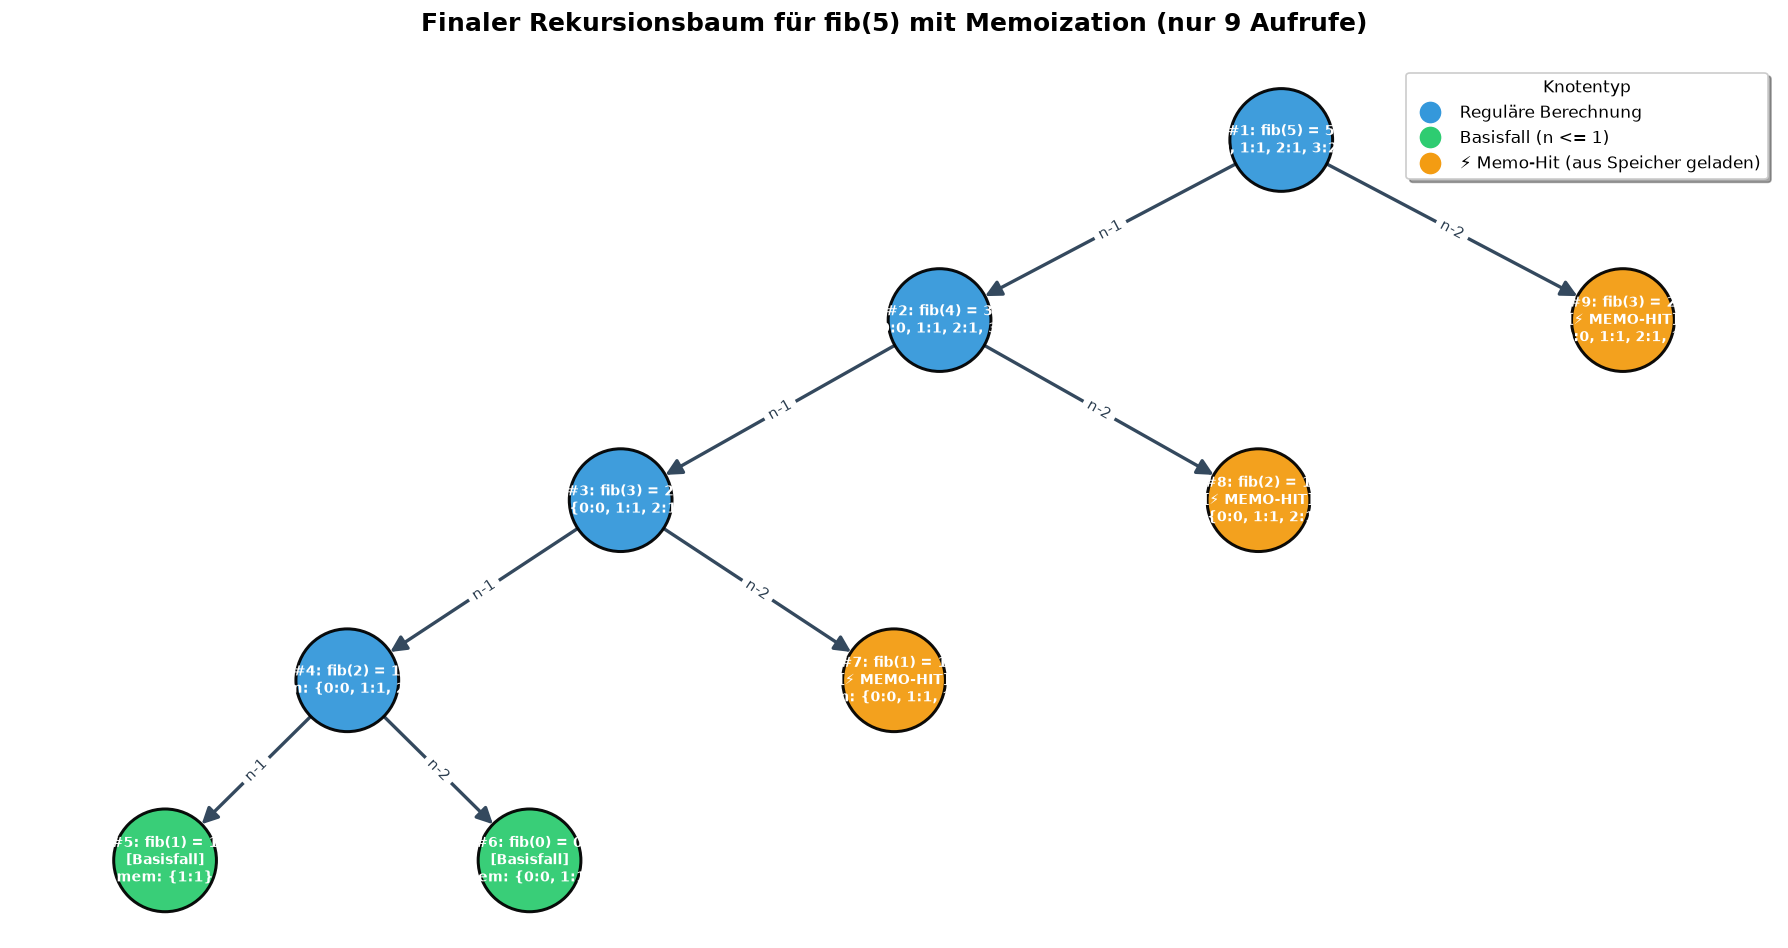

In [8]:
def draw_recursion_tree_memo(root):
    """Zeichnet den finalen Rekursionsbaum für Memoization."""
    G = nx.DiGraph()
    nodes_dict = {}
    edge_labels = {}

    def traverse(node):
        nodes_dict[node.node_id] = node
        G.add_node(node.node_id)
        for c in node.children:
            G.add_edge(node.node_id, c.node_id)
            edge_label = f"n-{node.n - c.n}"
            edge_labels[(node.node_id, c.node_id)] = edge_label
            traverse(c)

    traverse(root)
    pos = compute_tree_layout(root)

    # Knotenfarben: Memo-Hits = Gold/Gelb, Basisfälle = Grün, Regulär = Blau
    node_colors = []
    for uid in G.nodes():
        nd = nodes_dict[uid]
        if nd.is_memo_hit:
            node_colors.append("#f39c12")  # Gold für Memo-Hit
        elif nd.n <= 1:
            node_colors.append("#2ecc71")  # Grün für Basisfall
        else:
            node_colors.append("#3498db")  # Blau für reguläre Berechnung

    # Labels: ID, n, Wert und Memory-Zustand
    labels = {}
    for uid in G.nodes():
        nd = nodes_dict[uid]
        memo_keys = list(sorted(nd.memo_after.keys()))
        memo_short = "{" + ", ".join(f"{k}:{nd.memo_after[k]}" for k in memo_keys) + "}"
        if nd.is_memo_hit:
            labels[uid] = f"#{uid}: fib({nd.n}) = {nd.value}\n[⚡ MEMO-HIT]\nmem: {memo_short}"
        elif nd.n <= 1:
            labels[uid] = f"#{uid}: fib({nd.n}) = {nd.value}\n[Basisfall]\nmem: {memo_short}"
        else:
            labels[uid] = f"#{uid}: fib({nd.n}) = {nd.value}\nmem: {memo_short}"

    plt.figure(figsize=(15, 8))
    plt.title("Finaler Rekursionsbaum für fib(5) mit Memoization (nur 9 Aufrufe)", fontsize=15, fontweight="bold", pad=20)

    nx.draw_networkx_nodes(G, pos, node_color=node_colors, node_size=3800, alpha=0.95, edgecolors="black", linewidths=1.8)
    nx.draw_networkx_edges(G, pos, arrows=True, arrowstyle="-| >", arrowsize=20, edge_color="#34495e", width=2.0, node_size=3800)
    nx.draw_networkx_labels(G, pos, labels=labels, font_size=8.5, font_weight="bold", font_color="white")
    nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels, font_size=9, font_color="#2c3e50")

    # Legende
    legend_elements = [
        plt.Line2D([0], [0], marker="o", color="w", markerfacecolor="#3498db", markersize=14, label="Reguläre Berechnung"),
        plt.Line2D([0], [0], marker="o", color="w", markerfacecolor="#2ecc71", markersize=14, label="Basisfall (n <= 1)"),
        plt.Line2D([0], [0], marker="o", color="w", markerfacecolor="#f39c12", markersize=14, label="⚡ Memo-Hit (aus Speicher geladen)")
    ]
    plt.legend(handles=legend_elements, loc="upper right", title="Knotentyp", frameon=True, shadow=True)

    plt.axis("off")
    plt.tight_layout()
    plt.show()

draw_recursion_tree_memo(root_memo)


## 5. Direkter Vergleich beider finaler Rekursionsbäume nebeneinander

Um die drastische Reduktion des Suchraums und die Vermeidung redundanter Berechnungen unmittelbar zu erfassen, stellen wir beide Bäume im selben Maßstab nebeneinander dar.

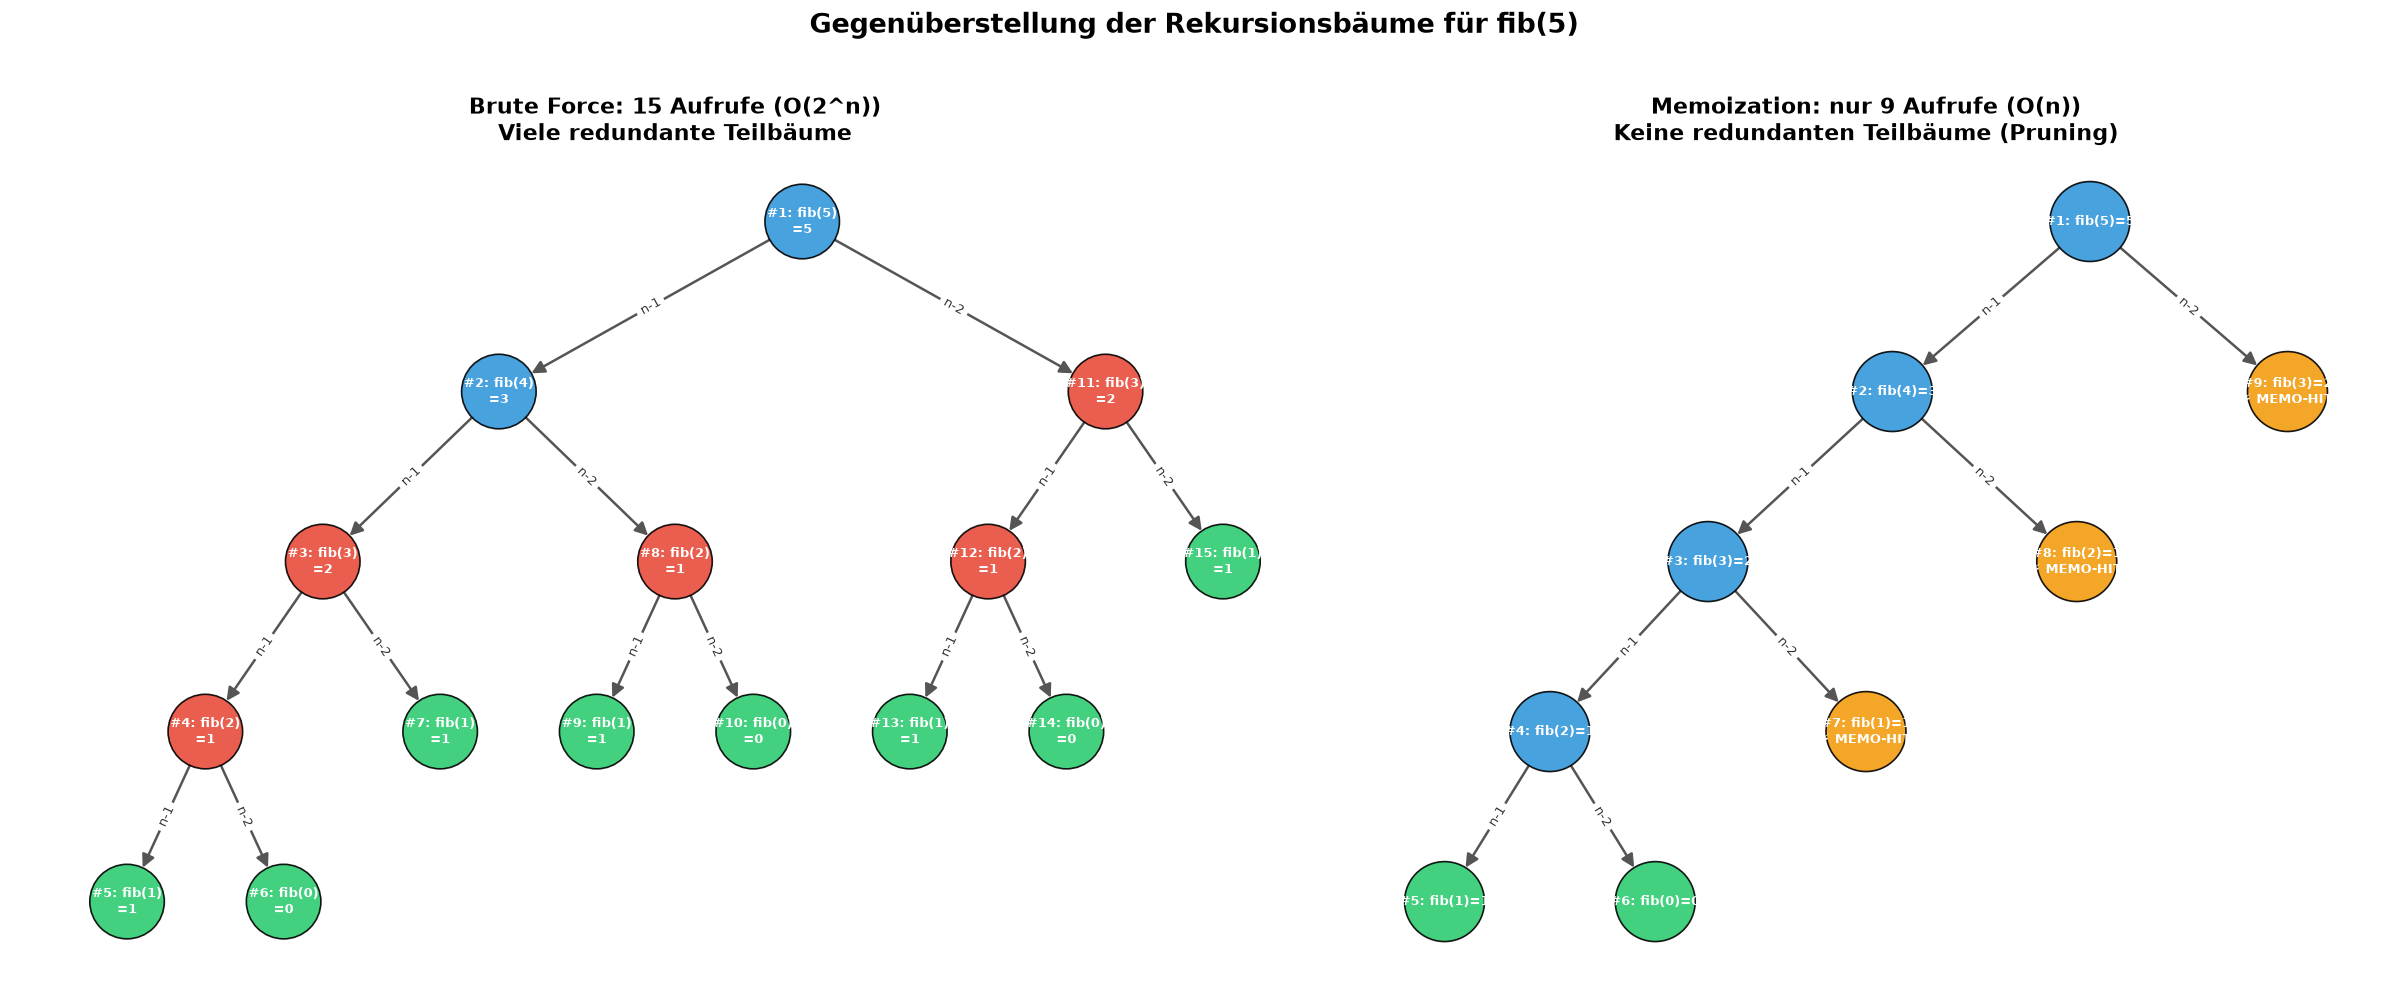

In [9]:
def compare_both_trees(root_bf, root_memo):
    """Visualisiert den Brute-Force- und den Memoization-Rekursionsbaum nebeneinander."""
    fig, (ax_bf, ax_memo) = plt.subplots(1, 2, figsize=(20, 8), gridspec_kw={"width_ratios": [1.3, 1]})

    # --- 1. Brute Force (Links) ---
    ax_bf.set_title("Brute Force: 15 Aufrufe (O(2^n))\nViele redundante Teilbäume", fontsize=13, fontweight="bold")
    G_bf = nx.DiGraph()
    nodes_bf = {}
    edge_labels_bf = {}

    def tr_bf(node):
        nodes_bf[node.node_id] = node
        G_bf.add_node(node.node_id)
        for c in node.children:
            G_bf.add_edge(node.node_id, c.node_id)
            edge_labels_bf[(node.node_id, c.node_id)] = f"n-{node.n - c.n}"
            tr_bf(c)

    tr_bf(root_bf)
    pos_bf = compute_tree_layout(root_bf)

    # Farbkodierung: Rot für redundante Teilprobleme (n=2 und n=3), Grün für Basisfälle
    colors_bf = []
    for uid in G_bf.nodes():
        n_val = nodes_bf[uid].n
        if n_val <= 1:
            colors_bf.append("#2ecc71")
        elif n_val in [2, 3]:
            colors_bf.append("#e74c3c")  # Markierung als mehrfach redundant berechnet
        else:
            colors_bf.append("#3498db")

    labels_bf = {uid: f"#{uid}: fib({nodes_bf[uid].n})\n={nodes_bf[uid].value}" for uid in G_bf.nodes()}

    nx.draw_networkx_nodes(G_bf, pos_bf, node_color=colors_bf, node_size=2000, alpha=0.9, edgecolors="black", ax=ax_bf)
    nx.draw_networkx_edges(G_bf, pos_bf, arrows=True, arrowstyle="-| >", arrowsize=16, edge_color="#555", width=1.5, node_size=2000, ax=ax_bf)
    nx.draw_networkx_labels(G_bf, pos_bf, labels=labels_bf, font_size=8, font_weight="bold", font_color="white", ax=ax_bf)
    nx.draw_networkx_edge_labels(G_bf, pos_bf, edge_labels=edge_labels_bf, font_size=8, font_color="#333", ax=ax_bf)
    ax_bf.axis("off")

    # --- 2. Memoization (Rechts) ---
    ax_memo.set_title("Memoization: nur 9 Aufrufe (O(n))\nKeine redundanten Teilbäume (Pruning)", fontsize=13, fontweight="bold")
    G_memo = nx.DiGraph()
    nodes_memo = {}
    edge_labels_memo = {}

    def tr_memo(node):
        nodes_memo[node.node_id] = node
        G_memo.add_node(node.node_id)
        for c in node.children:
            G_memo.add_edge(node.node_id, c.node_id)
            edge_labels_memo[(node.node_id, c.node_id)] = f"n-{node.n - c.n}"
            tr_memo(c)

    tr_memo(root_memo)
    pos_memo = compute_tree_layout(root_memo)

    colors_memo = []
    for uid in G_memo.nodes():
        nd = nodes_memo[uid]
        if nd.is_memo_hit:
            colors_memo.append("#f39c12")
        elif nd.n <= 1:
            colors_memo.append("#2ecc71")
        else:
            colors_memo.append("#3498db")

    labels_memo = {
        uid: (f"#{uid}: fib({nodes_memo[uid].n})={nodes_memo[uid].value}\n[⚡ MEMO-HIT]"
              if nodes_memo[uid].is_memo_hit else f"#{uid}: fib({nodes_memo[uid].n})={nodes_memo[uid].value}")
        for uid in G_memo.nodes()
    }

    nx.draw_networkx_nodes(G_memo, pos_memo, node_color=colors_memo, node_size=2300, alpha=0.9, edgecolors="black", ax=ax_memo)
    nx.draw_networkx_edges(G_memo, pos_memo, arrows=True, arrowstyle="-| >", arrowsize=16, edge_color="#555", width=1.5, node_size=2300, ax=ax_memo)
    nx.draw_networkx_labels(G_memo, pos_memo, labels=labels_memo, font_size=8, font_weight="bold", font_color="white", ax=ax_memo)
    nx.draw_networkx_edge_labels(G_memo, pos_memo, edge_labels=edge_labels_memo, font_size=8, font_color="#333", ax=ax_memo)
    ax_memo.axis("off")

    plt.suptitle("Gegenüberstellung der Rekursionsbäume für fib(5)", fontsize=16, fontweight="bold", y=1.02)
    plt.tight_layout()
    plt.show()

compare_both_trees(root_bf, root_memo)


## 6. Zusammenfassung und Komplexitätsvergleich

Die Gegenüberstellung zeigt anschaulich das Prinzip der dynamischen Programmierung:

In [10]:
summary_df = pd.DataFrame({
    "Kriterium": [
        "Ergebnis fib(5)",
        "Funktionsaufrufe insgesamt",
        "Berechnete Basisfälle (n=0, 1)",
        "Berechnungen innerer Knoten (n>=2)",
        "Memo-Hits (aus Speicher geladen)",
        "Maximale Rekursionstiefe",
        "Zeitkomplexität (allgemein für n)",
        "Speicherkomplexität (Call-Stack + Memo)"
    ],
    "Brute-Force Rekursion": [
        str(root_bf.value),
        "15",
        "8 (5x fib(1), 3x fib(0))",
        "7 (1x fib(5), 2x fib(4), 3x fib(3), 1x fib(2))",
        "0 (kein Speicher)",
        "4",
        "O(2^n)",
        "O(n) (nur Stack)"
    ],
    "Memoization (Top-Down DP)": [
        str(root_memo.value),
        "9",
        "2 (1x fib(1), 1x fib(0))",
        "4 (1x fib(2), 1x fib(3), 1x fib(4), 1x fib(5))",
        "3 (fib(1), fib(2), fib(3))",
        "4",
        "O(n)",
        "O(n) (Stack + Dict)"
    ]
})

display(summary_df)


,Kriterium,Brute-Force Rekursion,Memoization (Top-Down DP)
0,Ergebnis fib(5),5,5
1,Funktionsaufrufe insgesamt,15,9
2,"Berechnete Basisfälle (n=0, 1)","8 (5x fib(1), 3x fib(0))","2 (1x fib(1), 1x fib(0))"
3,Berechnungen innerer Knoten (n>=2),"7 (1x fib(5), 2x fib(4), 3x fib(3), 1x fib(2))","4 (1x fib(2), 1x fib(3), 1x fib(4), 1x fib(5))"
4,Memo-Hits (aus Speicher geladen),0 (kein Speicher),"3 (fib(1), fib(2), fib(3))"
5,Maximale Rekursionstiefe,4,4
6,Zeitkomplexität (allgemein für n),O(2^n),O(n)
7,Speicherkomplexität (Call-Stack + Memo),O(n) (nur Stack),O(n) (Stack + Dict)
